# El motor de referencia ORE, QuantLib y lo que queda fuera de línea

- **Nivel:** 3, comparación con métodos publicados
- **Requisitos previos:** los notebooks 02 y 06 de este tema
- **Tiempo de lectura:** unos 50 minutos

**Pregunta:** ¿Para qué carteras del caso la exposición del motor coincide con el motor de referencia de código abierto ORE dentro del error de Monte Carlo, dónde deja de coincidir y por cuántos errores estándar, y qué dicen las formas cerradas de QuantLib sobre las fórmulas de Hull-White que hay debajo?

## Objetivos

Al terminar este notebook puedes:

- decir qué ofrecen el Open Source Risk Engine (ORE) y QuantLib para la exposición de contraparte, y qué no ofrece ninguno;
- leer una conciliación de un perfil de exposición contra ORE en errores estándar combinados de Monte Carlo, y calcularla desde los arreglos versionados;
- decir en cuáles de las seis variantes del caso C12 el motor coincide con ORE, en cuáles no, y qué dice el documento sobre las causas;
- leer la comparación de las formas cerradas de Hull-White del motor con las de QuantLib, y el triángulo forma cerrada, simulación y ORE;
- decir qué queda fuera de línea en el producto, y por qué.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw
from riskvalidation.validation import ccr as vc

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son las seis variantes del caso C12 (riesgo de crédito de contraparte): el swap único, el conjunto de neteo de cuatro swaps, el CSA con 10 y con 20 días hábiles, el CSA con margen inicial, y la variante de correlación adversa. Las operaciones son convenciones sintéticas, la curva es la curva a la par del Tesoro de EE. UU. del 2025-09-30 (clase de licencia `mirror-allowed`). Cada documento tiene el bloque `ore_reconciliation`: el perfil que ORE 1.8.17.0 produjo para las mismas operaciones y curva (10.000 muestras antitéticas, corrido de forma nativa con la rueda de Python, no en este notebook), la coincidencia punto a punto y el estado.

- **Archivos que se leen:** los seis documentos bajo `data/derived/C12/`, claves `outputs.exposure`, `outputs.ore_reconciliation`, `outputs.initial_margin` y `tests`. ORE no está instalado ni se corre aquí: es una rueda nativa de 77,6 MB que queda fuera de línea, y sus archivos de configuración están bajo control de versiones en el proceso de generación de datos como evidencia de lo que se corrió (`data-pipeline/pipeline/cases/c12/ore_inputs/`).
- **Estado de verdad:** `synthetic-calibrated`. Lo que muestra una conciliación es la coincidencia entre dos implementaciones del mismo modelo sobre las mismas entradas, no que el modelo sea correcto (el notebook 06 muestra que no lo es).

La celda siguiente carga los seis documentos e imprime el estado de cada conciliación.

In [2]:
# Cargar las seis variantes versionadas de C12 e imprimir el estado ORE de cada una
ROOT = Path("../../..").resolve()
names = ["single-swap", "netting-set", "csa-mpor-10d", "csa-mpor-20d", "with-im", "wrong-way-risk"]
docs = {n: json.loads((ROOT / "data" / "derived" / "C12" / f"{n}.json").read_text(encoding="utf-8")) for n in names}
LIGHT = {"green": "verde", "red": "rojo", "amber": "ámbar"}
baked = docs["single-swap"]["provenance"]["riskvalidation_version"]
print("calculado con riskvalidation", baked, "| instalado", rv.__version__)
STATUS = {"reconciled": "conciliada", "not-applicable": "no aplicable"}

print(f"{'variante':16s}{'estado':16s}{'todo en 2 se':>20s}{'corrida ORE, s':>18s}")
for n in names:
    o = docs[n]["outputs"]["ore_reconciliation"]
    seconds = round(o["run_seconds"], 1) if o["run_seconds"] else "-"
    status = STATUS[o["status"]]
    inside = {True: "sí", False: "no", None: "-"}[o["all_within_two_se"]]
    print(f"{n:16s}{status:16s}{inside:>20s}{seconds!s:>18}")
print("ORE versión:", docs["single-swap"]["outputs"]["ore_reconciliation"]["ore_version"])
print("variante sin conciliación con ORE, y por qué:",
      docs["wrong-way-risk"]["outputs"]["ore_reconciliation"]["reason"]["es"])

calculado con riskvalidation 1.0.1 | instalado 1.0.1
variante        estado                  todo en 2 se    corrida ORE, s
single-swap     conciliada                        sí              18.1
netting-set     conciliada                        sí              23.6
csa-mpor-10d    conciliada                        no              48.8
csa-mpor-20d    conciliada                        no              53.2
with-im         conciliada                        no              48.7
wrong-way-risk  no aplicable                       -                 -
ORE versión: 1.8.17.0
variante sin conciliación con ORE, y por qué: El ejemplo de riesgo de correlación adversa de ORE es otro modelo (un LGM de crédito correlacionado), no el modelo de intensidad de incumplimiento de Hull y White (2012) sobre el valor del portafolio, por lo que esta variante no tiene conciliación con ORE.


## Método

### Paso 1: el lado del motor, simulado y en forma cerrada

El lado del producto en la comparación es la exposición del swap único, calculada de dos maneras con el motor: simulando la tasa corta de Hull-White (notebook 01), y con la forma cerrada según la cual la exposición de un swap pagador es el pago de una swaption pagadora sobre el swap restante, valorada con la descomposición de Jamshidian, $EE_B(t) = \mathrm{Swaption}(0; t) / P(0, t)$ (notebook 06). La identidad vale en las fechas de reinicio del swap. La celda siguiente reconstruye la simulación con la curva, la calibración, la semilla y la grilla del caso.

In [3]:
# Reconstruir la simulación del swap único con la curva, la calibración, la semilla y la grilla del caso
single = docs["single-swap"]["outputs"]
base = docs["netting-set"]["outputs"]
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
swaps = [
    sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer",
            t["start_years"], t["maturity_years"], t["fixed_frequency_per_year"])
    for t in base["book"]["trades"]
]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in (14 / 360, 28 / 360)]), 12))
grid = sw.simulation_grid(merged, swaps)
n_paths, seed = named["path_count"]["value"], named["seed"]["value"]
r = hw1f.simulate_short_rate(grid, a, sigma, forward, n_paths, seed)
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)
p0r = p0(report)
ee_d, ee_d_se = ex.expected_exposure(values[0][:, ix], numeraire[:, ix])
ee_sim, ee_sim_se = ee_d / p0r, ee_d_se / p0r
print("trayectorias:", n_paths, "| semilla:", seed, "| fechas del informe:", report.size)
print("EE simulada, máximo:", round(float(ee_sim.max()), 0), "en", float(report[ee_sim.argmax()]), "a")

trayectorias: 20000 | semilla: 42 | fechas del informe: 33
EE simulada, máximo: 294524.0 en 5.0 a


La celda siguiente calcula la EE de forma cerrada del swap en sus fechas de reinicio y mide su distancia a la EE simulada en errores estándar de Monte Carlo.

In [4]:
# La EE de forma cerrada del swap único en sus fechas de reinicio, y su distancia a la EE simulada
swap = swaps[0]
resets = sw.reset_times(swap)
pick = [k for k, t in enumerate(report) if np.min(np.abs(resets - t)) < 1e-9]
analytic = ex.analytic_ee_single_swap(swap, report[pick], a, sigma, p0, forward)
test1 = vc.ee_analytic_vs_simulated(analytic * p0r[pick], ee_d[pick], ee_d_se[pick], 3.0)
k_1y, k_5y = [pick.index(np.searchsorted(report, y - 1e-9)) for y in (1.0, 5.0)]
print("fechas de la verificación de forma cerrada:", len(pick))
print("EE analítica a 1 a y 5 a:", np.round(analytic[[k_1y, k_5y]], 0))
print("mayor brecha con la EE simulada, en errores estándar:", round(test1.statistic, 3))

fechas de la verificación de forma cerrada: 19
EE analítica a 1 a y 5 a: [141685. 295711.]
mayor brecha con la EE simulada, en errores estándar: 0.891


## Comparación

Qué ofrece el mundo de código abierto para la exposición de contraparte, tal como la investigación persistida del caso lo registra desde las fuentes primarias (la metodología y la versión de ORE en la etiqueta 1.8.17.0, el repositorio y el índice de paquetes de QuantLib, el marco de Basilea) y tal como este producto lo usa.

- **ORE (Open Source Risk Engine), 1.8.17.0.** Un motor en C++ con licencia BSD modificada, con una rueda de Python (una rueda nativa de 77,6 MB, Windows, Linux y macOS). Simula la exposición bajo un modelo de tasa de interés Linear Gauss Markov, calcula EE, ENE, PFE y EEPE, CVA, DVA, FVA, MVA y KVA, SA-CCR y BA-CVA, y tiene un margen inicial dinámico por regresión y un módulo ISDA SIMM. Su metodología describe **dos formas de modelar el período de riesgo de margen**: el enfoque preferido de cierre, con una grilla auxiliar desplazada por el MPoR respecto de la grilla de incumplimiento (el que sigue Contraste, con el valor de fecha pegajosa), y un enfoque heredado con rezago. Es la referencia abierta más completa de lo que calcula el caso.
- **QuantLib.** Curvas, instrumentos, motores de valoración y modelos de tasa corta, con opciones sobre bonos de Hull-White en forma cerrada y un motor de swaptions de Jamshidian, contra los que se verifican las formas cerradas del motor. QuantLib **no tiene un flujo empaquetado de exposición ni de XVA**: el lazo de exposición sobre él lo escribe el usuario.
- **La brecha.** La investigación no encontró un motor abierto maduro para el lado del libro bancario (gestión de activos y pasivos, liquidez) contra el cual conciliar; para la exposición de contraparte ORE es la referencia, y la regla de la investigación es que Contraste no debe declarar validados los números de ORE más allá de las conciliaciones que realmente corre.
- **Lo que queda fuera.** La metodología ISDA SIMM se publica bajo un aviso que restringe su uso a las operaciones propias de un participante, así que sus pesos de riesgo no se reimplementan ni se publican en un producto abierto; el margen inicial dinámico por regresión de ORE hace sus veces y se rotula como aproximación. Las cronologías de Andersen, Pykhtin y Sokol (2017) del período de riesgo de margen no se modelan. Las curvas de crédito reales de contrapartes no son públicas: la aproximación es un promedio de mercado.
- **Lo que queda fuera de línea en el producto.** ORE, un motor nativo de decenas de megabytes, corre solo en el proceso de generación de datos y sus resultados se versionan; el navegador lee los documentos versionados. Las simulaciones de este tema corren en segundos, pero la prueba retrospectiva de 309 fechas con sus valores críticos simulados toma minutos y también se versiona.
- **Dónde está Contraste respecto de esto.** El motor implementa en Python, con pruebas propias, la simulación de Hull-White, las garantías, el CVA y la correlación adversa, concilia con ORE y QuantLib donde ellos dan un número, y declara dónde no (correlación adversa: el ejemplo de ORE es otro modelo). El notebook 08 usa eso como una afirmación.

Los tres pasos siguientes corren la comparación con esa referencia: el perfil del motor contra el de ORE, los números que importan para el capital, y las formas cerradas contra QuantLib.

### Paso 2: el perfil de EE contra ORE

ORE y el motor dan cada uno una estimación de la misma exposición esperada en 33 fechas, con un error de Monte Carlo. `reconcile_ee_profile`, del motor, toma los dos perfiles con sus errores y devuelve, como estadístico, la mayor brecha en **errores estándar combinados**

$$z_k = \frac{|EE_k - EE^{ORE}_k|}{\sqrt{se_k^2 + se_k^{ORE\,2}}}$$

con un umbral interno de Contraste de 2 para verde (un umbral, no uno regulatorio). Ambos perfiles son la EE sin descontar en medida forward del documento: el perfil descontado de ORE dividido por $P(0,t)$, la misma transformación por la que pasa el perfil del motor. La celda siguiente calcula el estadístico de las cinco variantes que tienen referencia, desde los arreglos versionados.

In [5]:
# El estadístico de reconcile_ee_profile de cada variante desde los arreglos de EE de ambos motores
checked = [n for n in names if docs[n]["outputs"]["ore_reconciliation"]["status"] != "not-applicable"]
k1 = 11
z = {}
print(f"{'variante':14s}{'estadístico':>12s}{'puntos en 2 se':>20s}{'luz':>8s}"
      f"{'ORE/Python 1 y':>16s}{'z medio':>10s}")
for n in checked:
    o = docs[n]["outputs"]
    ee, ee_se = np.array(o["exposure"]["ee"]["values"]), np.array(o["exposure"]["ee"]["mc_se"])
    ore = o["ore_reconciliation"]
    ref, ref_se = np.array(ore["ore_ee"]["values"]), np.array(ore["ore_ee"]["mc_se"])
    t = vc.reconcile_ee_profile(ee, ee_se, ref, ref_se, k_se=2.0)
    z[n] = (ee - ref) / np.sqrt(ee_se**2 + ref_se**2)
    inside = int(np.sum(np.abs(z[n]) <= 2))
    ratio_1y = ref[k1] / ee[k1]
    print(f"{n:14s}{t.statistic:12.3f}{inside:16d} /{ee.size:3d}{LIGHT[t.light.value]:>8s}", end="")
    print(f"{ratio_1y:16.4f}{float(z[n].mean()):10.2f}")
mta0 = [r for r in docs["csa-mpor-10d"]["tests"] if r["segment"] == "minimum-transfer-amount-0"][0]
print("fila de diagnóstico, CSA de 10 días con monto mínimo de transferencia cero en ambos motores:",
      round(mta0["statistic"], 3), LIGHT[mta0["light"]])
print("lo que dice el documento sobre el monto mínimo de transferencia:",
      docs["csa-mpor-10d"]["outputs"]["collateral"]["limit"]["es"])

variante       estadístico      puntos en 2 se     luz  ORE/Python 1 y   z medio
single-swap          0.775              33 / 33   verde          1.0040     -0.17
netting-set          0.715              33 / 33   verde          1.0042     -0.18
csa-mpor-10d         9.931              17 / 33    rojo          0.9868      2.38
csa-mpor-20d         7.086              21 / 33    rojo          0.9988      1.47
with-im             11.739              32 / 33    rojo          0.8936      0.19
fila de diagnóstico, CSA de 10 días con monto mínimo de transferencia cero en ambos motores: 3.637 rojo
lo que dice el documento sobre el monto mínimo de transferencia: No se modelan las cronologías de Andersen, Pykhtin y Sokol. El monto mínimo de transferencia actúa sobre el saldo de la grilla del informe; ORE margina con su propio calendario de llamadas, por lo que su efecto es mayor allí (véase las filas de ORE).


La celda siguiente dibuja la diferencia estandarizada entre el motor y ORE a lo largo de las fechas para el swap único, el CSA de 10 días y el CSA con margen inicial, frente a la banda de dos errores estándar.

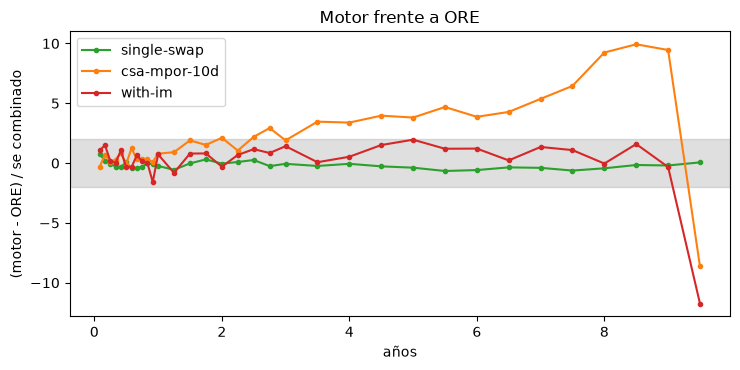

In [6]:
# Dibujar (motor - ORE) / se combinado a lo largo de las fechas para tres variantes
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for n, color in (("single-swap", "tab:green"), ("csa-mpor-10d", "tab:orange"), ("with-im", "tab:red")):
    dates = np.array(docs[n]["outputs"]["exposure"]["time_grid_years"])
    ax.plot(dates, z[n], "o-", ms=3, color=color, label=n)
ax.axhspan(-2, 2, color="grey", alpha=0.25)
ax.set_xlabel("años")
ax.set_ylabel("(motor - ORE) / se combinado")
ax.set_title("Motor frente a ORE")
ax.legend()
fig.tight_layout()
plt.show()

La línea verde, el swap único, queda dentro de la banda gris en las 33 fechas y oscila alrededor de cero, que es lo que deben hacer dos estimaciones de la misma cantidad. La línea naranja, el CSA, sale de la banda en muchas fechas y lo hace hacia un solo lado, de modo que el motor y ORE discrepan de forma sistemática y no por ruido. La línea roja, el CSA con margen inicial, está dentro de la banda salvo en unas pocas fechas donde salta por encima de diez. La figura mide el desacuerdo y no decide quién tiene razón, pues ORE tampoco es un oráculo; el documento deja ambas brechas como hallazgos.

### Paso 3: la EEPE, el CVA y el margen inicial dinámico

La misma comparación se aplica a los números que importan para el capital. El documento registra, para cada variante, la EEPE y el CVA de ambos motores con su error combinado (`eepe_agreement`, `cva_agreement`), y para la variante con margen inicial el perfil del margen inicial dinámico medio del `dim_cube` de ORE contra el del motor. La celda siguiente imprime la diferencia de cada uno en errores estándar combinados, con la luz versionada,, la razón de los dos DIM medios y el estadístico de la conciliación del motor aplicado al perfil del DIM.

In [7]:
# EEPE y CVA del motor y de ORE en errores estándar combinados; luego el DIM medio de ambos
print(f"{'variante':14s}{'EEPE Py':>10s}{'EEPE ORE':>10s}{'z':>8s}{'luz':>8s}", end="")
print(f"{'CVA Py':>10s}{'CVA ORE':>10s}{'z':>8s}{'luz':>8s}")
tests = ("ccr.ore_eepe_agreement", "ccr.ore_cva_agreement")
zs = {}
for n in checked:
    o = docs[n]["outputs"]["ore_reconciliation"]
    e, c = o["eepe_agreement"], o["cva_agreement"]
    lights = {row["test_id"]: row["light"] for row in docs[n]["tests"] if row["test_id"] in tests}
    zs[n] = (e["difference"] / e["combined_se"], c["difference"] / c["combined_se"])
    print(f"{n:14s}{e['python']:10.1f}{e['ore']:10.1f}{zs[n][0]:8.2f}{LIGHT[lights[tests[0]]]:>8s}"
          f"{c['python']:10.2f}{c['ore']:10.2f}{zs[n][1]:8.2f}{LIGHT[lights[tests[1]]]:>8s}")

im = docs["with-im"]["outputs"]
ore_im, py_im = im["ore_reconciliation"], im["initial_margin"]
dim_py, dim_py_se = np.array(py_im["dim"]["values"]), np.array(py_im["dim"]["mc_se"])
dim_ore, dim_ore_se = np.array(ore_im["ore_dim"]["values"]), np.array(ore_im["ore_dim"]["mc_se"])
t_dim = vc.reconcile_ee_profile(dim_py, dim_py_se, dim_ore, dim_ore_se, k_se=2.0)
ratio = dim_ore / dim_py
print("DIM medio a 1 a, motor y ORE:", round(dim_py[k1], 0), round(dim_ore[k1], 0))
print("razón DIM de ORE / motor: media, menor, mayor:",
      round(float(ratio.mean()), 3), round(float(ratio.min()), 3), round(float(ratio.max()), 3))
print("mayor brecha del DIM en errores estándar combinados:", round(t_dim.statistic, 1), LIGHT[t_dim.light.value])

variante         EEPE Py  EEPE ORE       z     luz    CVA Py   CVA ORE       z     luz
single-swap      87550.9   87810.5    0.30   verde  10337.65  10371.78    0.37   verde
netting-set      59954.1   60157.2    0.31   verde   9477.77   9510.70    0.40   verde
csa-mpor-10d     22777.8   22527.8   -1.55   verde    699.53    653.89  -15.89    rojo
csa-mpor-20d     33183.5   32665.3   -2.20    rojo   1011.72    973.14   -9.88    rojo
with-im            212.9     198.0   -0.71   verde      7.02      6.69   -1.40   verde
DIM medio a 1 a, motor y ORE: 110493.0 104805.0
razón DIM de ORE / motor: media, menor, mayor: 0.884 0.692 0.997
mayor brecha del DIM en errores estándar combinados: 137.4 rojo


La celda siguiente dibuja la diferencia entre el motor y ORE para la EEPE y para el CVA de cada variante, en errores estándar combinados.

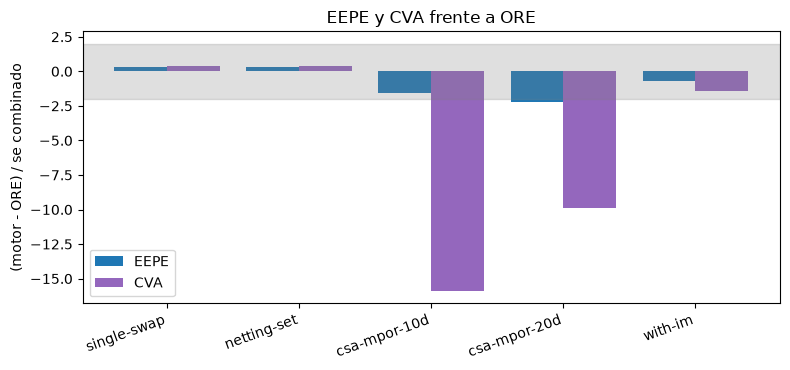

In [8]:
# Dibujar las diferencias de EEPE y CVA entre el motor y ORE de cada variante en errores estándar combinados
x = np.arange(len(checked))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - 0.2, [zs[n][0] for n in checked], width=0.4, color="tab:blue", label="EEPE")
ax.bar(x + 0.2, [zs[n][1] for n in checked], width=0.4, color="tab:purple", label="CVA")
ax.axhspan(-2, 2, color="grey", alpha=0.25)
ax.set_xticks(x, checked, rotation=20, ha="right")
ax.set_ylabel("(ORE - motor) / se combinado".replace("ORE - motor", "motor - ORE"))
ax.set_title("EEPE y CVA frente a ORE")
ax.legend()
fig.tight_layout()
plt.show()

Las dos primeras variantes quedan dentro de la banda para ambos números. Para los CSA la EEPE está en el límite (dentro en el de 10 días, apenas fuera en el de 20 días) pero el CVA está muy afuera, a unos diez a dieciséis errores estándar, con ORE dando el CVA menor. El CVA es el número más sensible a la parte inicial del perfil, donde actúa el monto mínimo de transferencia, por lo que el CVA expone un desacuerdo que la EEPE casi oculta. Con margen inicial los dos números son pequeños y ambos están dentro. Las barras comparan dos motores, no un motor y la verdad.

### Paso 4: las formas cerradas contra QuantLib, y el triángulo

La opción sobre bono y la swaption de Jamshidian de Hull-White del motor se comparan con QuantLib 1.44 (`HullWhite.discountBondOption` y `JamshidianSwaptionEngine`) al generar el documento, en cuatro filas cuyo umbral es una diferencia relativa de $10^{-6}$; QuantLib no está instalado aquí, así que leemos las filas que el documento versionó, con ambos valores. Luego cerramos el triángulo para el swap único: la EE analítica (que no necesita simulación), la EE simulada del motor y la de ORE, en las fechas de reinicio. Si las tres coinciden dentro de sus errores, tres rutas independientes (una forma cerrada, una simulación en Python y una simulación en un motor C++) dan la misma exposición.

In [9]:
# Las cuatro filas de QuantLib, luego la forma cerrada, la simulación y ORE sobre el swap único
for row in docs["single-swap"]["tests"]:
    if row["test_id"].startswith("ccr.quantlib"):
        x = row["extras"]
        rel = abs(x["engine"] - x["quantlib"]) / abs(x["quantlib"])
        print(f"{row['test_id']:30s} motor {x['engine']:12.6f} | QuantLib {x['quantlib']:12.6f}"
              f" | diferencia relativa {rel:.1e} | {LIGHT[row['light']]}")

ore = single["ore_reconciliation"]
ore_ee, ore_se = np.array(ore["ore_ee"]["values"])[pick], np.array(ore["ore_ee"]["mc_se"])[pick]
sim, sim_se = ee_sim[pick], ee_sim_se[pick]
print("fechas del triángulo:", len(pick))
no_se = np.zeros(len(pick))
sim_vs_closed = vc.reconcile_ee_profile(sim, sim_se, analytic, no_se, k_se=2.0)
ore_vs_closed = vc.reconcile_ee_profile(ore_ee, ore_se, analytic, no_se, k_se=2.0)
ore_vs_sim = vc.reconcile_ee_profile(ore_ee, ore_se, sim, sim_se, k_se=2.0)
print("mayor simulación - forma cerrada, en errores estándar:", round(sim_vs_closed.statistic, 3))
print("mayor ORE - forma cerrada, en errores estándar:", round(ore_vs_closed.statistic, 3))
print("mayor ORE - simulación, en errores estándar combinados:", round(ore_vs_sim.statistic, 3))

ccr.quantlib_bond_call         motor     0.039287 | QuantLib     0.039287 | diferencia relativa 0.0e+00 | verde
ccr.quantlib_bond_put          motor     0.035838 | QuantLib     0.035838 | diferencia relativa 0.0e+00 | verde
ccr.quantlib_swaption_payer    motor  7010.256951 | QuantLib  7010.256285 | diferencia relativa 9.5e-08 | verde
ccr.quantlib_swaption_receiver motor 11140.502980 | QuantLib 11140.503857 | diferencia relativa 7.9e-08 | verde
fechas del triángulo: 19
mayor simulación - forma cerrada, en errores estándar: 0.891
mayor ORE - forma cerrada, en errores estándar: 0.465
mayor ORE - simulación, en errores estándar combinados: 0.659


La celda siguiente dibuja la EE del swap único por las tres rutas en las fechas de reinicio.

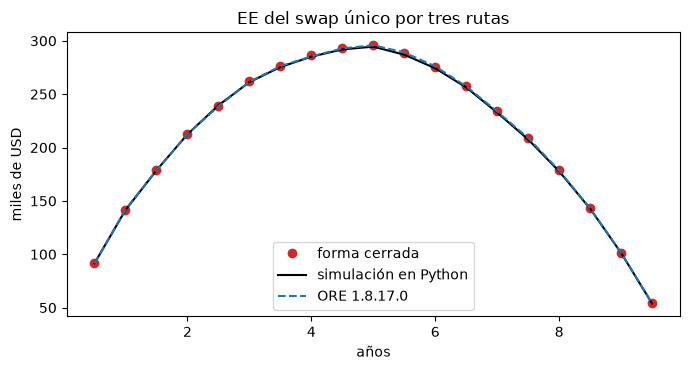

In [10]:
# Dibujar la EE del swap único por la forma cerrada, la simulación en Python y ORE
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(report[pick], analytic / 1e3, "o", color="tab:red", label="forma cerrada")
ax.plot(report[pick], sim / 1e3, "-", color="black", label="simulación en Python")
ax.plot(report[pick], ore_ee / 1e3, "--", color="tab:blue", label="ORE 1.8.17.0")
ax.set_xlabel("años")
ax.set_ylabel("miles de USD")
ax.set_title("EE del swap único por tres rutas")
ax.legend()
fig.tight_layout()
plt.show()

Las tres curvas no se distinguen a simple vista, y los números de arriba dejan la mayor distancia entre dos cualesquiera de ellas por debajo de un error estándar combinado. Una forma cerrada, una simulación en Python y una simulación en C++, escritas de forma independiente, dan la misma exposición para un swap sin garantía, así que las fórmulas de Hull-White del motor están implementadas de manera consistente. Las filas de QuantLib dicen lo mismo de las formas cerradas por separado. Lo que la imagen no puede mostrar es cartera alguna con garantía, donde las rutas divergen, ni si el propio modelo de Hull-White describe el mercado.

## Resultados

**Respuesta:** El motor coincide con ORE en las carteras sin garantía y no en las que tienen márgenes. Para el swap único y el conjunto de neteo de cuatro swaps la mayor brecha del perfil de EE es 0,775 y 0,715 errores estándar combinados, dentro del umbral de 2 en las 33 fechas; para el CSA de 10 días es 9,931, para el CSA de 20 días 7,086 y con margen inicial 11,739, y el margen inicial dinámico medio de ORE es en promedio 0,884 del del motor. En el swap único la forma cerrada, la simulación y ORE coinciden dentro de 0,891 errores estándar, y las swaptions del motor coinciden con QuantLib hasta una diferencia relativa de 9,5e-8.

- **Las carteras simples coinciden con ORE.** La EEPE difiere en 0,30 y 0,31 errores estándar (87.551 contra 87.811 USD, y 59.954 contra 60.157 USD), y el CVA en 0,37 y 0,40 (10.338 contra 10.372 USD, y 9.478 contra 9.511 USD).
- **Las carteras con garantía no.** Para el CSA de 10 días el perfil de EE coincide solo en 17 de 33 fechas, la EEPE está dentro del umbral (-1,55) pero el CVA no: ORE da 653,89 USD frente a 699,53 del motor, una brecha de 15,9 errores estándar combinados. Para 20 días el perfil coincide en 21 de 33 fechas, y tanto la EEPE (-2,20) como el CVA (-9,88) están en rojo. La lectura del documento es que el monto mínimo de transferencia actúa sobre el saldo de la grilla del informe en el motor, mientras que ORE margina con su propio calendario de llamadas, por lo que su efecto es mayor en ORE.
- **Margen inicial.** Con margen inicial el perfil después del margen coincide en 32 de 33 fechas, y la EEPE y el CVA están en verde (-0,71 y -1,40), pero el margen inicial dinámico medio no: el de ORE es en promedio 0,884 del del motor, 104.805 contra 110.493 USD a un año. El documento marca la causa como NO VERIFICADA y anota que la exposición esperada después del margen coincide, así que las dos estimaciones del margen difieren donde la exposición posterior al margen lo oculta.
- **La correlación adversa no tiene referencia.** El ejemplo de correlación adversa de ORE es otro modelo (un factor de crédito correlacionado con la tasa), así que la variante lleva `not-applicable` y su verificación es el Apéndice del artículo (notebooks 03 y 08).
- **QuantLib.** La opción call y put sobre bono coinciden con QuantLib 1.44 hasta el último dígito y las swaptions pagadora y receptora hasta 9,5e-8 y 7,9e-8 en términos relativos, muy dentro del umbral de 1e-6.

Lo que este notebook no muestra: no corre ORE ni QuantLib (quedan fuera de línea y el documento versiona lo que dieron), y no dice qué motor tiene razón donde difieren; el documento deja las brechas del CSA y del DIM como hallazgos.

## Resumen

- ORE es la referencia abierta más completa para la exposición de contraparte; QuantLib da las formas cerradas de Hull-White pero ningún flujo de exposición; ambos quedan fuera de línea, y el producto versiona lo que produjeron.
- La conciliación es un estadístico en errores estándar combinados de Monte Carlo con un umbral de 2: el swap único y el conjunto de neteo pasan (mayor brecha 0,78), las variantes de CSA y el margen inicial dinámico no (mayores brechas 9,9, 7,1 y 137).
- La forma cerrada, la simulación en Python y ORE coinciden dentro de un error estándar en el swap único, así que el modelo está implementado de manera consistente; donde entra la garantía los motores difieren y el documento lo informa.
- Una conciliación compara dos implementaciones del mismo modelo; no dice nada sobre si el modelo se ajusta al mercado (notebook 06).

**Qué probar después.** Calcula los mismos estadísticos con solo las primeras 16 fechas y mira cómo el número de puntos mueve el máximo; mira en `data-pipeline/pipeline/cases/c12/ore_inputs/` los archivos de configuración que produjeron el perfil de ORE. Luego sigue con el notebook 08.

## Referencias

- Open Source Risk Engine (ORE), release 1.8.17.0. https://github.com/OpenSourceRisk/Engine
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- QuantLib, the open-source quantitative finance library. https://github.com/lballabio/QuantLib
- Andersen, L., Pykhtin, M. and Sokol, A. (2017), Rethinking the margin period of risk, Journal of Credit Risk 13(1). https://doi.org/10.21314/JCR.2016.218
- Hull, J. and White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4), 573-592. https://doi.org/10.1093/rfs/3.4.573
- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605